# Dataset diagnostics

This notebook visualizes all synthetic dataset variants and both peaked outcome-shape variants:
- `wu2024_original`
- `wu2024_biased_assignment`
- `wu2024_nonadditive` (inspected in the final separate section)
- `wu2024_single_peaked_heterogeneous_nonadditive_shifted` (inspected in the final separate section)
- `wu2024_saturated_interaction`
- `wu2024_saturated_interaction_biased_assignment`
- `peaked`
- `peaked_centered`

It shows optimal treatment, assignment mean, latent confounder effects, confounding strength, conditional distributions, and pairwise scatter plots. Each figure is also exported in both PNG and PDF with dataset- and structure-specific filenames.

In [1]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == 'notebooks' else Path.cwd().resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.notebook_helpers import make_simulator, plot_dataset_diagnostics, plot_population_ate_curve, plot_conditional_distributions, plot_pairwise_scatters, plot_optimal_vs_observed, plot_optimal_vs_x0, label_and_save_figure

versions = ['wu2024_original', 'wu2024_biased_assignment', 'wu2024_saturated_interaction', 'wu2024_saturated_interaction_biased_assignment']
structure_types = ['peaked', 'peaked_centered']
figure_output_dir = PROJECT_ROOT / 'outputs' / 'notebook_dataset_diagnostics'

In [ ]:
for structure_type in structure_types:
    for version in versions:
        simulator, train_sample, test_sample = make_simulator(version=version, seed=13, n_train=1200, n_test=3000, structure_type=structure_type)
        print('\n===', version, '|', structure_type, '===')
        print('support:', simulator.support)
        print('overlap rate:', simulator.overlap_rate(train_sample))
        print('mean |A-a*|:', abs(train_sample.treatment.reshape(-1) - train_sample.optimal_treatment.reshape(-1)).mean())
        figures = [
            ('dataset_diagnostics', plot_dataset_diagnostics(simulator, train_sample)),
            ('population_ate_curve', plot_population_ate_curve(simulator, train_sample)),
            ('optimal_vs_observed', plot_optimal_vs_observed(train_sample)),
            ('optimal_vs_x0', plot_optimal_vs_x0(train_sample)),
            ('conditional_distributions', plot_conditional_distributions(train_sample)),
            ('pairwise_scatters', plot_pairwise_scatters(train_sample)),
        ]
        for figure_kind, fig in figures:
            png_path, pdf_path = label_and_save_figure(fig, figure_output_dir, version, structure_type, figure_kind)
            print('saved:', png_path.name, 'and', pdf_path.name)
            display(fig)
            plt.close(fig)


In [ ]:
baseline_structure_type = 'quardratic'
for version in versions:
    simulator, train_sample, _ = make_simulator(version=version, seed=13, n_train=1200, n_test=3000, structure_type=baseline_structure_type)
    print('\n===', version, '|', baseline_structure_type, '===')
    print('support:', simulator.support)
    print('overlap rate:', simulator.overlap_rate(train_sample))
    print('mean |A-a*|:', abs(train_sample.treatment.reshape(-1) - train_sample.optimal_treatment.reshape(-1)).mean())
    figures = [
        ('dataset_diagnostics', plot_dataset_diagnostics(simulator, train_sample)),
        ('population_ate_curve', plot_population_ate_curve(simulator, train_sample)),
        ('optimal_vs_observed', plot_optimal_vs_observed(train_sample)),
        ('optimal_vs_x0', plot_optimal_vs_x0(train_sample)),
        ('conditional_distributions', plot_conditional_distributions(train_sample)),
        ('pairwise_scatters', plot_pairwise_scatters(train_sample)),
    ]
    for figure_kind, fig in figures:
        png_path, pdf_path = label_and_save_figure(fig, figure_output_dir, version, baseline_structure_type, figure_kind)
        print('saved:', png_path.name, 'and', pdf_path.name)
        display(fig)
        plt.close(fig)


In [ ]:
baseline_structure_type = 'sigmoid'
for version in versions:
    simulator, train_sample, _ = make_simulator(version=version, seed=13, n_train=1200, n_test=3000, structure_type=baseline_structure_type)
    print('\n===', version, '|', baseline_structure_type, '===')
    print('support:', simulator.support)
    print('overlap rate:', simulator.overlap_rate(train_sample))
    print('mean |A-a*|:', abs(train_sample.treatment.reshape(-1) - train_sample.optimal_treatment.reshape(-1)).mean())
    figures = [
        ('dataset_diagnostics', plot_dataset_diagnostics(simulator, train_sample)),
        ('population_ate_curve', plot_population_ate_curve(simulator, train_sample)),
        ('optimal_vs_observed', plot_optimal_vs_observed(train_sample)),
        ('optimal_vs_x0', plot_optimal_vs_x0(train_sample)),
        ('conditional_distributions', plot_conditional_distributions(train_sample)),
        ('pairwise_scatters', plot_pairwise_scatters(train_sample)),
    ]
    for figure_kind, fig in figures:
        png_path, pdf_path = label_and_save_figure(fig, figure_output_dir, version, baseline_structure_type, figure_kind)
        print('saved:', png_path.name, 'and', pdf_path.name)
        display(fig)
        plt.close(fig)


## Nonadditive Wu Outcome Confounding Variant

This final section inspects `wu2024_nonadditive` separately. Tune these parameters directly in the next cell:
- `nonadditive_gamma`: scales latent confounding strength (higher -> stronger `U_z` impact on outcome).
- `nonadditive_scale_ratio`: controls the confounding scale `s` (lower -> larger confounding term away from the support center).
- `centered_penalty_strength`: narrows and sharpens `peaked_centered` around support center.
- `nonadditive_eta`, `nonadditive_outcome_noise_scale`: optional interaction/noise controls.

$$
\gamma\left(\frac{A-m}{s}\right)^2(1+\eta X_0)U_Z,
\quad m=\frac{a_{\min}+a_{\max}}{2},
\quad s=\texttt{nonadditive\_scale\_ratio}(a_{\max}-a_{\min}).
$$

The treatment assignment stays the same as in the original Wu generator; this section changes the outcome confounding profile and centered peak shape.


=== wu2024_nonadditive | single_peaked_heterogeneous ===
gamma=0.9, eta=0.0, scale_ratio=0.12, center=0.4947, scale=0.4469
corr(latent_term, U_z)=0.9564
corr(latent_term, additive_Uz)=0.9564


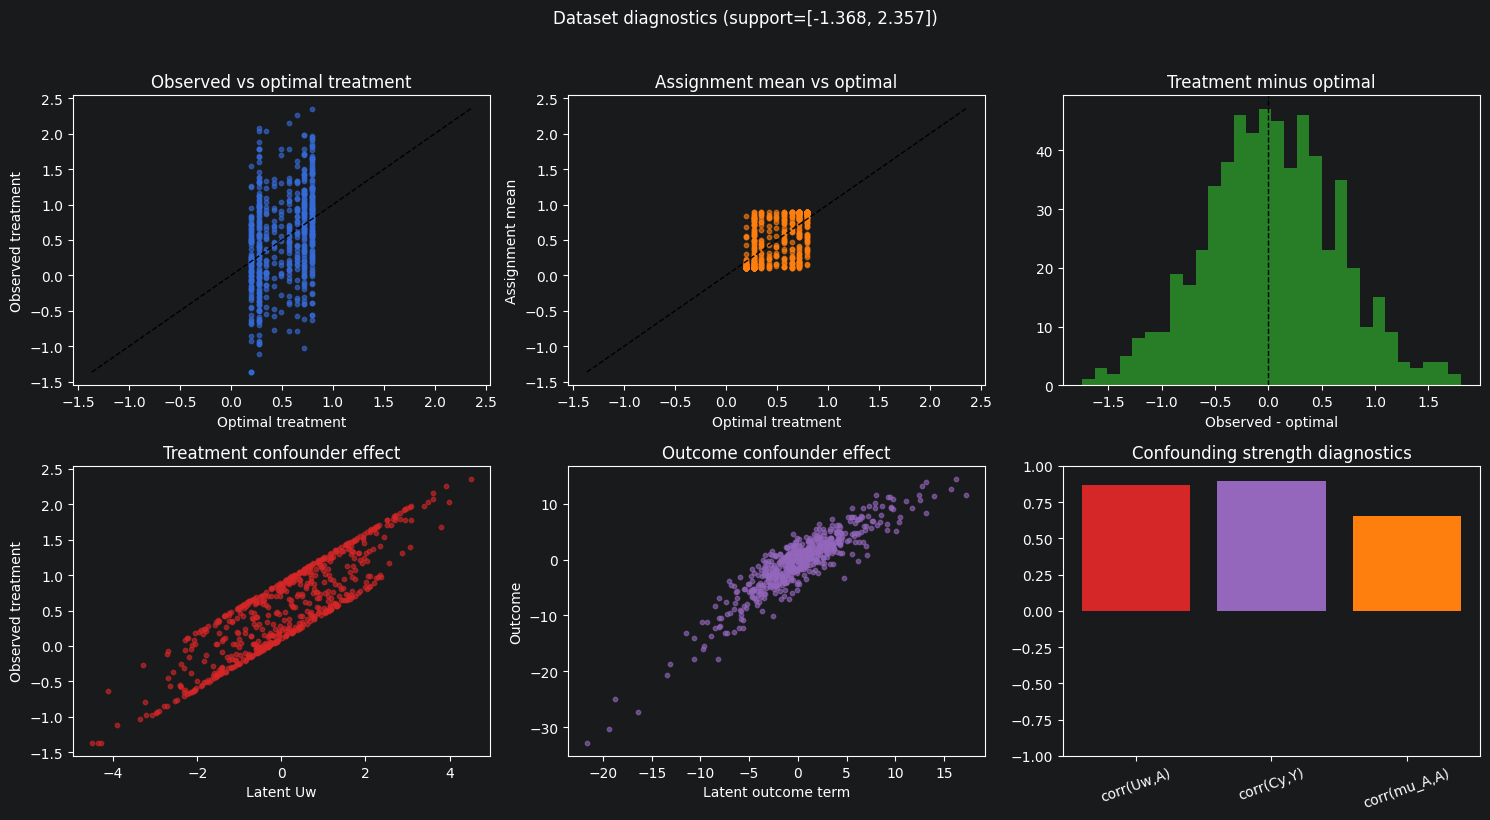

saved: wu2024_nonadditive__single_peaked_heterogeneous__dataset_diagnostics.png and wu2024_nonadditive__single_peaked_heterogeneous__dataset_diagnostics.pdf


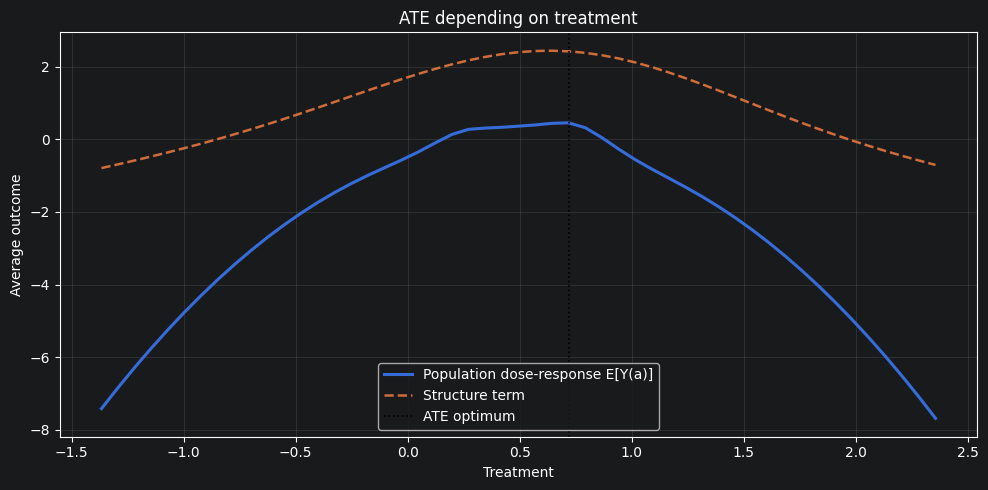

saved: wu2024_nonadditive__single_peaked_heterogeneous__population_ate_curve.png and wu2024_nonadditive__single_peaked_heterogeneous__population_ate_curve.pdf


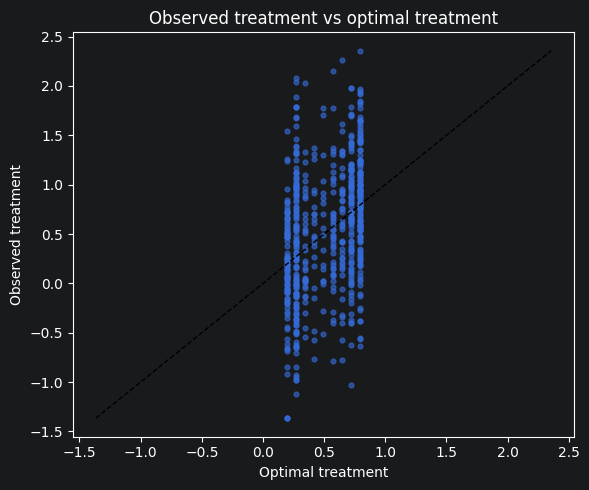

saved: wu2024_nonadditive__single_peaked_heterogeneous__optimal_vs_observed.png and wu2024_nonadditive__single_peaked_heterogeneous__optimal_vs_observed.pdf


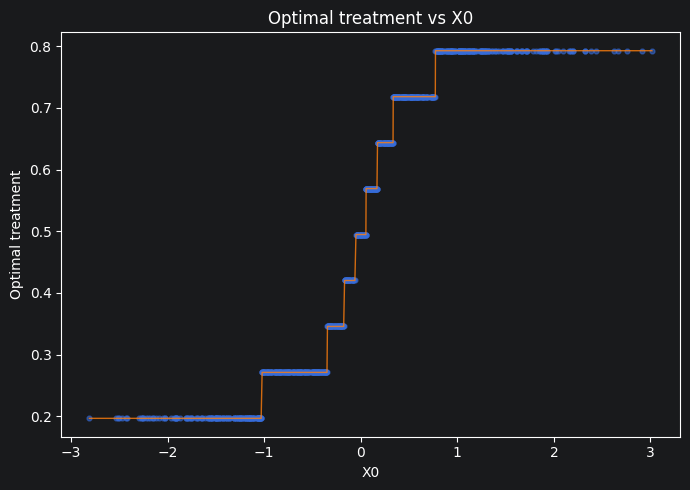

saved: wu2024_nonadditive__single_peaked_heterogeneous__optimal_vs_x0.png and wu2024_nonadditive__single_peaked_heterogeneous__optimal_vs_x0.pdf


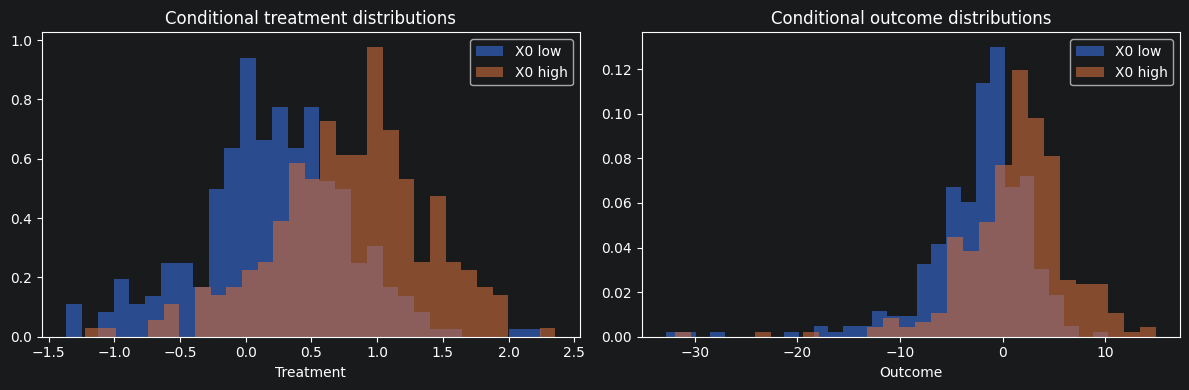

saved: wu2024_nonadditive__single_peaked_heterogeneous__conditional_distributions.png and wu2024_nonadditive__single_peaked_heterogeneous__conditional_distributions.pdf


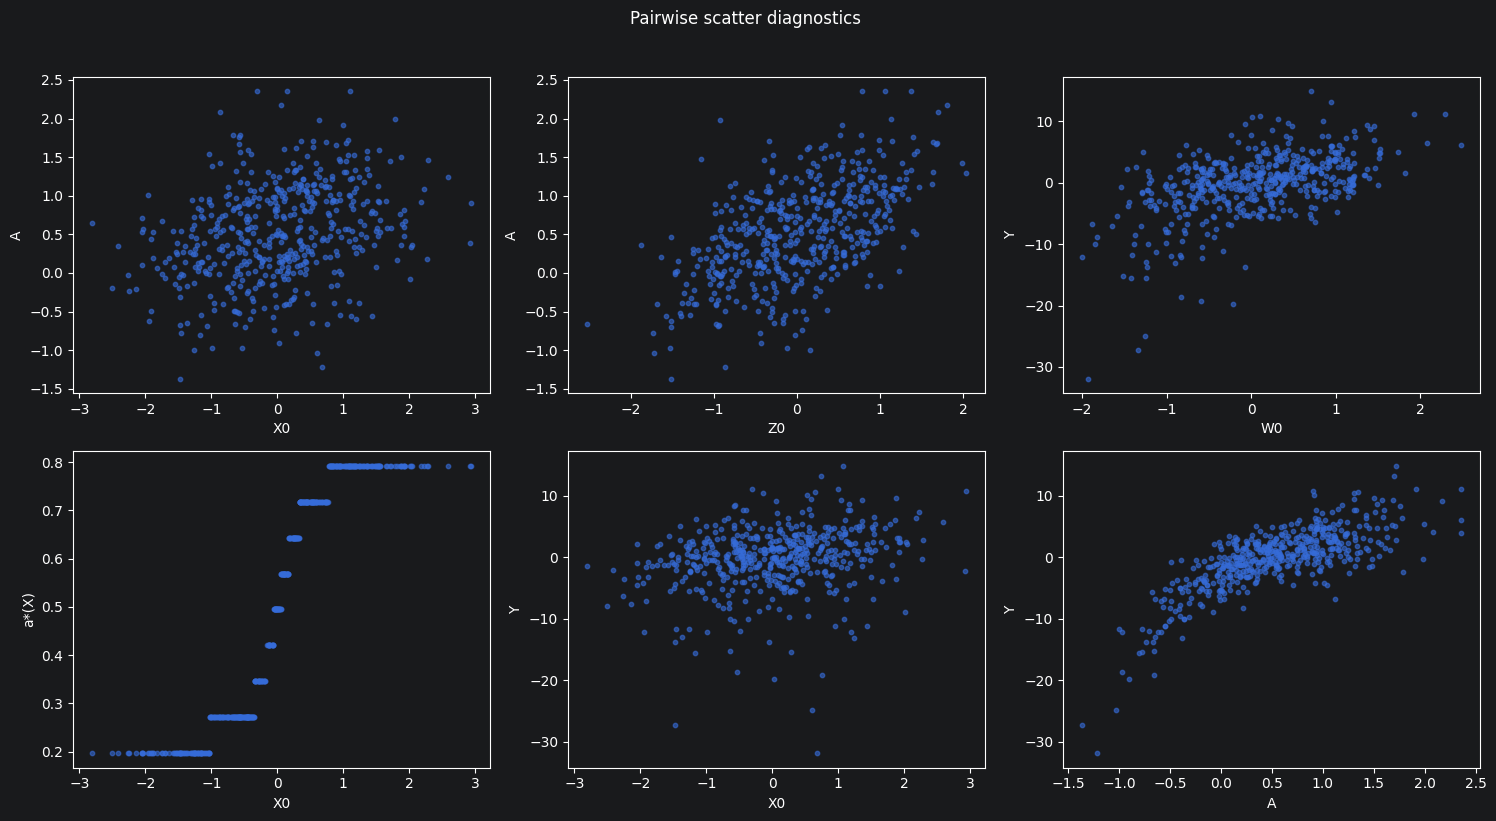

saved: wu2024_nonadditive__single_peaked_heterogeneous__pairwise_scatters.png and wu2024_nonadditive__single_peaked_heterogeneous__pairwise_scatters.pdf


In [4]:
# Editable parameters for nonadditive diagnostics (base + shifted)
import numpy as np

# Main controls
nonadditive_gamma = 0.9
nonadditive_eta = 0.0
nonadditive_scale_ratio = 0.12
centered_penalty_strength = 1.5

# Optional controls
nonadditive_outcome_noise_scale = 0.0
nonadditive_structure_type = 'single_peaked_heterogeneous'
additive_term_scale = 1.0

nonadditive_versions = [
    'wu2024_nonadditive'
]

for version in nonadditive_versions:
    simulator, train_sample, _ = make_simulator(
        version=version,
        seed=13,
        n_train=1200,
        n_test=3000,
        structure_type=nonadditive_structure_type,
        nonadditive_gamma=nonadditive_gamma,
        nonadditive_eta=nonadditive_eta,
        nonadditive_scale_ratio=nonadditive_scale_ratio,
        centered_penalty_strength=centered_penalty_strength,
        outcome_noise_scale=nonadditive_outcome_noise_scale,
        additive_term_scale=additive_term_scale,
    )

    m = 0.5 * (simulator.support[0] + simulator.support[1])
    s = simulator.config.nonadditive_confounding_scale_ratio * (simulator.support[1] - simulator.support[0])
    latent_term = simulator.latent_outcome_confounding_term(
        train_sample.treatment,
        train_sample.covariates,
        train_sample.latent_uz,
    )
    additive_term = additive_term_scale * train_sample.latent_uz.reshape(-1)

    print(f'=== {version} | {nonadditive_structure_type} ===')
    print(f'gamma={nonadditive_gamma}, eta={nonadditive_eta}, scale_ratio={nonadditive_scale_ratio}, center={m:.4f}, scale={s:.4f}')
    print(f'corr(latent_term, U_z)={np.corrcoef(latent_term.reshape(-1), train_sample.latent_uz.reshape(-1))[0,1]:.4f}')
    print(f'corr(latent_term, additive_Uz)={np.corrcoef(latent_term.reshape(-1), additive_term)[0,1]:.4f}')

    figures = [
        ('dataset_diagnostics', plot_dataset_diagnostics(simulator, train_sample)),
        ('population_ate_curve', plot_population_ate_curve(simulator, train_sample)),
        ('optimal_vs_observed', plot_optimal_vs_observed(train_sample)),
        ('optimal_vs_x0', plot_optimal_vs_x0(train_sample)),
        ('conditional_distributions', plot_conditional_distributions(train_sample)),
        ('pairwise_scatters', plot_pairwise_scatters(train_sample)),
    ]

    for figure_kind, fig in figures:
        display(fig)
        png_path, pdf_path = label_and_save_figure(
            fig,
            figure_output_dir,
            version,
            nonadditive_structure_type,
            figure_kind,
        )
        print('saved:', png_path.name, 'and', pdf_path.name)
        plt.close(fig)


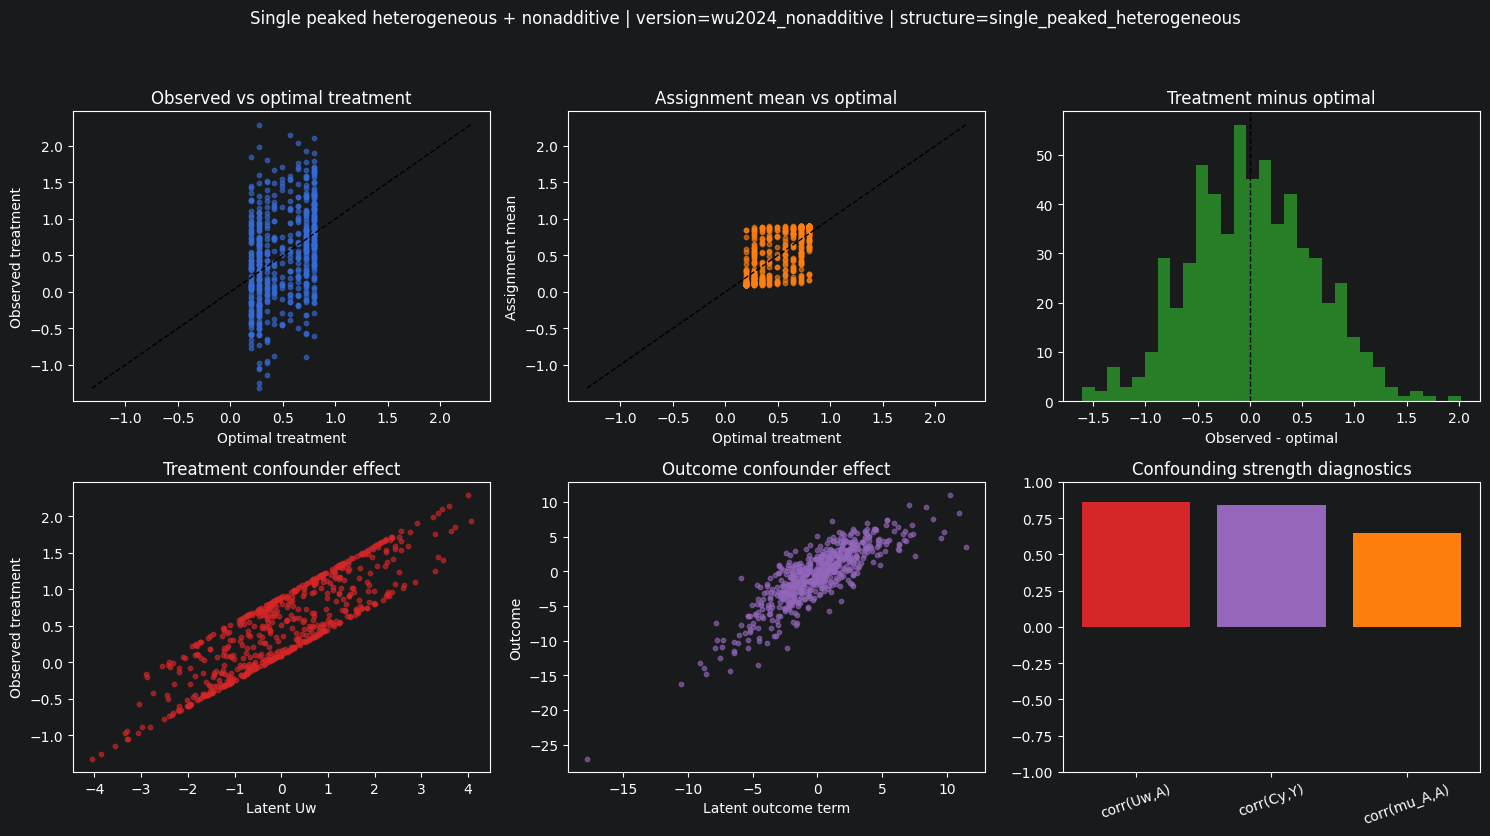

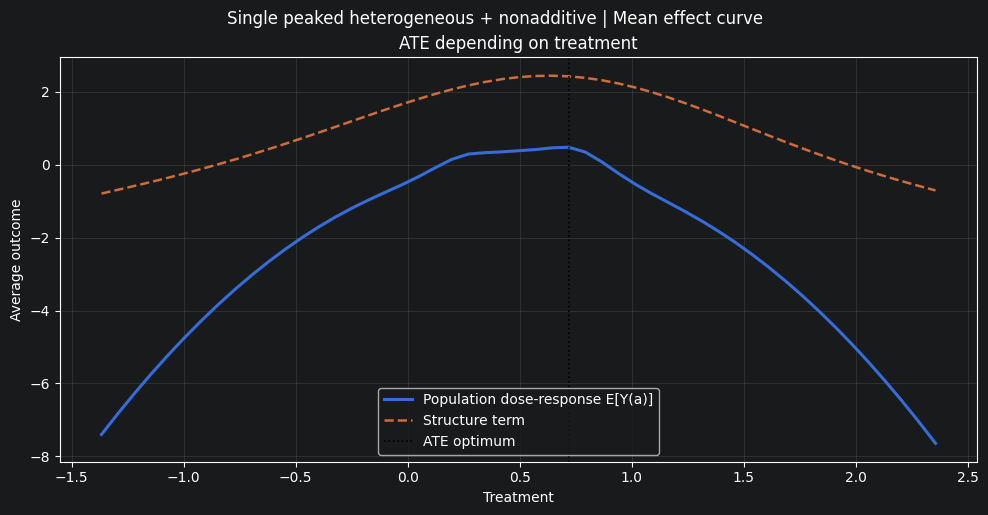

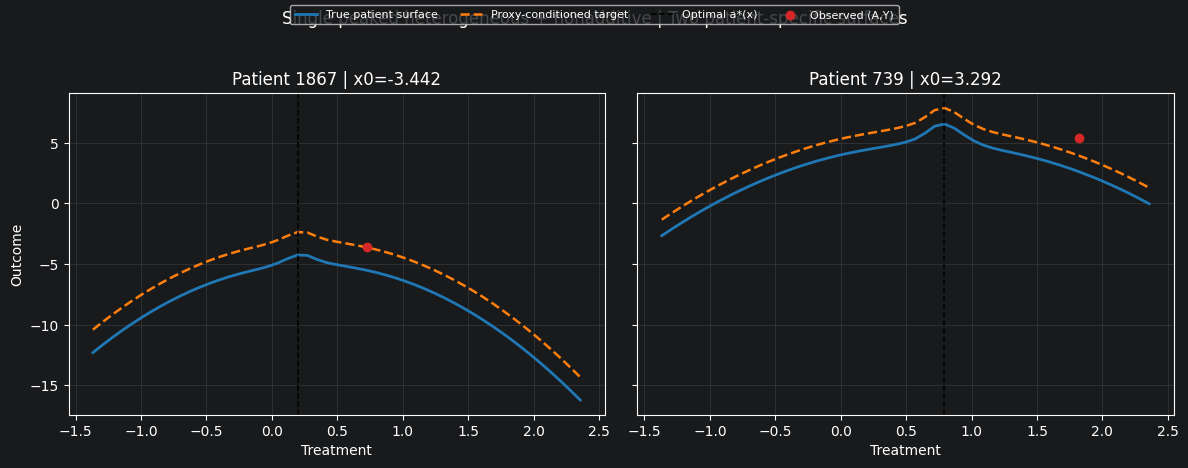

In [5]:
# Added: single-peaked diagnostics
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display

# Ensure project root is importable when notebook is run from notebooks/.
_cwd = Path.cwd()
for _base in [_cwd, *_cwd.parents]:
    if (_base / 'src').exists():
        if str(_base) not in sys.path:
            sys.path.insert(0, str(_base))
        break

from src.notebook_helpers import (
    label_and_save_figure,
    make_simulator,
    plot_dataset_diagnostics,
    plot_population_ate_curve,
)

single_peak_variants = [
    ('wu2024_nonadditive', 'single_peaked_heterogeneous', 'Single peaked heterogeneous + nonadditive'),
]

fig_dir = Path('pdfs')
fig_dir.mkdir(parents=True, exist_ok=True)

for dataset_version, structure_type, label in single_peak_variants:
    sim, train_sample, _ = make_simulator(
        version=dataset_version,
        structure_type=structure_type,
        n_train=2000,
        n_test=1000,
    )

    # 1) Dataset diagnostics panel
    fig_diag = plot_dataset_diagnostics(sim, train_sample, max_points=600)
    fig_diag.suptitle(f'{label} | version={dataset_version} | structure={structure_type}', y=1.04)
    display(fig_diag)
    label_and_save_figure(fig_diag, fig_dir, dataset_version, structure_type, 'dataset_diagnostics_single_peak')
    plt.close(fig_diag)

    # 2) Mean effect curve
    fig_mean = plot_population_ate_curve(sim, train_sample)
    fig_mean.suptitle(f'{label} | Mean effect curve', y=1.02)
    display(fig_mean)
    label_and_save_figure(fig_mean, fig_dir, dataset_version, structure_type, 'mean_effect_curve')
    plt.close(fig_mean)

    # 3) Two patient-specific surfaces + proxy-conditioned target
    x0 = train_sample.covariates[:, 0]
    patient_indices = [int(np.argmin(x0)), int(np.argmax(x0))]
    a_grid = sim.policy_grid.reshape(-1)

    fig_pat, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
    for ax, pid in zip(axes, patient_indices):
        x_row = train_sample.covariates[pid:pid+1]
        w_row = train_sample.outcome_proxy[pid:pid+1]
        x_rep = np.repeat(x_row, a_grid.shape[0], axis=0)
        w_rep = np.repeat(w_row, a_grid.shape[0], axis=0)
        true_curve = sim.mean_outcome(a_grid, x_rep).reshape(-1)
        proxy_target_curve = sim.proxy_conditioned_outcome(a_grid, x_rep, w_rep).reshape(-1)
        factual_a = float(train_sample.treatment[pid, 0])
        factual_y = float(train_sample.outcome[pid, 0])
        optimal_a = float(train_sample.optimal_treatment[pid, 0])

        ax.plot(a_grid, true_curve, color='tab:blue', linewidth=2.0, label='True patient surface')
        ax.plot(a_grid, proxy_target_curve, color='tab:orange', linestyle='--', linewidth=1.8, label='Proxy-conditioned target')
        ax.axvline(optimal_a, color='k', linestyle='--', linewidth=1.1, label='Optimal a*(x)')
        ax.scatter([factual_a], [factual_y], color='tab:red', s=36, zorder=5, label='Observed (A,Y)')
        ax.set_title(f'Patient {pid} | x0={x0[pid]:.3f}')
        ax.set_xlabel('Treatment')
        ax.grid(alpha=0.2)

    axes[0].set_ylabel('Outcome')
    handles, labels = axes[0].get_legend_handles_labels()
    if handles:
        fig_pat.legend(handles, labels, loc='upper center', ncol=4, fontsize=8)
    fig_pat.suptitle(f'{label} | Two patient-specific surfaces', y=1.03)
    fig_pat.tight_layout()
    display(fig_pat)
    label_and_save_figure(fig_pat, fig_dir, dataset_version, structure_type, 'two_patient_surfaces')
    plt.close(fig_pat)


In [ ]:
# Updated: shifted presets diagnostics (shift latente por U_z)
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

from src.config import DataConfig
from src.data.simulator import Wu2024Simulator

shift_presets = {
    "right_mild": {
        "shifted_confounder_treatment_scale": 0.18,
        "shifted_confounder_treatment_slope": 1.2,
    },
    "right_strong": {
        "shifted_confounder_treatment_scale": 0.34,
        "shifted_confounder_treatment_slope": 2.1,
    },
    "left_mild": {
        "shifted_confounder_treatment_scale": -0.18,
        "shifted_confounder_treatment_slope": 1.2,
    },
    "left_strong": {
        "shifted_confounder_treatment_scale": -0.34,
        "shifted_confounder_treatment_slope": 2.1,
    },
}

for preset_name, preset in shift_presets.items():
    cfg = DataConfig(
        version="wu2024_single_peaked_heterogeneous_nonadditive_shifted",
        structure_type="single_peaked_heterogeneous",
        n_train=2500,
        n_test=1000,
        policy_grid_size=101,
        outcome_noise_scale=0.0,
        nonadditive_confounding_gamma=1.0,
        nonadditive_confounding_eta=0.0,
        nonadditive_confounding_scale_ratio=0.15,
        alpha_nonadditivity=0.45,
        shifted_confounder_treatment_scale=preset["shifted_confounder_treatment_scale"],
        shifted_confounder_treatment_slope=preset["shifted_confounder_treatment_slope"],
    )
    sim = Wu2024Simulator(cfg)
    sample = sim.sample_factual(cfg.n_test, seed=17)

    pid = int(np.argmax(np.abs(sample.latent_uz.reshape(-1))))
    x_i = sample.covariates[pid:pid + 1]
    w_i = sample.outcome_proxy[pid:pid + 1]
    uz_i = float(sample.latent_uz[pid, 0])

    grid = sim.policy_grid
    x_grid = np.repeat(x_i, grid.size, axis=0)
    w_grid = np.repeat(w_i, grid.size, axis=0)

    proxy_curve = sim.proxy_conditioned_outcome(grid, x_grid, w_grid)
    oracle_curve = sim.oracle_conditioned_outcome(grid, x_grid, w_grid, np.full(grid.size, uz_i))

    a_proxy = float(grid[np.argmax(proxy_curve)])
    a_oracle = float(grid[np.argmax(oracle_curve)])

    fig, ax = plt.subplots(1, 1, figsize=(7.0, 4.0))
    ax.plot(grid, proxy_curve, color="tab:blue", lw=2.0, label="proxy-conditioned")
    ax.plot(grid, oracle_curve, color="tab:red", lw=2.1, label=f"oracle-conditioned (U_z={uz_i:+.2f})")
    ax.axvline(a_proxy, color="tab:blue", ls=":", alpha=0.9)
    ax.axvline(a_oracle, color="tab:red", ls=":", alpha=0.9)
    ax.set_title(
        f"{preset_name} | scale={preset['shifted_confounder_treatment_scale']:+.2f}, "
        f"slope={preset['shifted_confounder_treatment_slope']:.1f} | "
        f"argmax diff={abs(a_oracle - a_proxy):.3f}"
    )
    ax.set_xlabel("Treatment a")
    ax.set_ylabel("Outcome")
    ax.grid(alpha=0.2)
    ax.legend(loc="best")
    plt.show()

    display(
        {
            "preset": preset_name,
            "pid": pid,
            "u_z": uz_i,
            "argmax_proxy": a_proxy,
            "argmax_oracle": a_oracle,
            "abs_diff": abs(a_oracle - a_proxy),
        }
    )



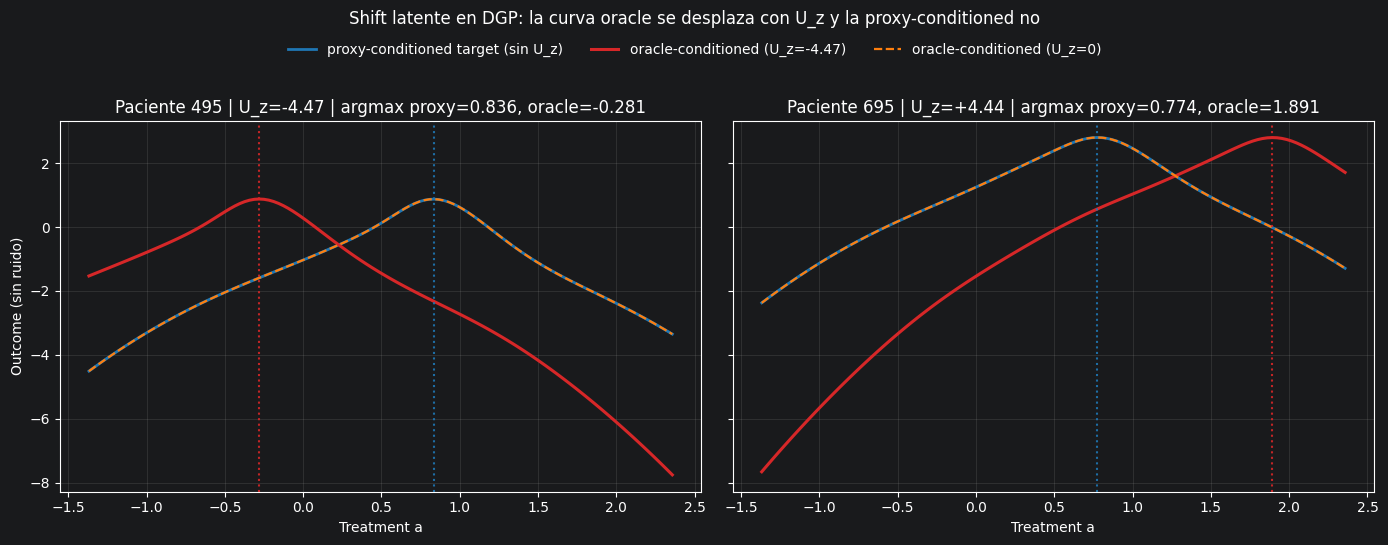

In [17]:
# Rehecha: diagnostico del dataset shifted con shift latente (U_z)
import numpy as np
import matplotlib.pyplot as plt

from src.config import DataConfig
from src.data.simulator import Wu2024Simulator

cfg = DataConfig(
    version="wu2024_single_peaked_heterogeneous_nonadditive_shifted",
    structure_type="single_peaked_heterogeneous",
    n_train=3500,
    n_test=1200,
    policy_grid_size=121,
    outcome_noise_scale=0.0,
    nonadditive_confounding_gamma=0.1,
    nonadditive_confounding_eta=0.0,
    nonadditive_confounding_scale_ratio=0.15,
    alpha_nonadditivity=0.1,
    shifted_confounder_treatment_scale=0.3,
    shifted_confounder_treatment_slope=1.8,
)

sim = Wu2024Simulator(cfg)
sample = sim.sample_factual(cfg.n_test, seed=7)
grid = sim.policy_grid

# Elegimos dos pacientes con U_z en colas opuestas para visualizar el desplazamiento horizontal.
uz_flat = sample.latent_uz.reshape(-1)
idx_left = int(np.argmin(uz_flat))
idx_right = int(np.argmax(uz_flat))
patient_ids = [idx_left, idx_right]

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, pid in zip(axes, patient_ids):
    x_i = sample.covariates[pid:pid + 1]
    w_i = sample.outcome_proxy[pid:pid + 1]
    uz_i = float(sample.latent_uz[pid, 0])

    x_grid = np.repeat(x_i, grid.size, axis=0)
    w_grid = np.repeat(w_i, grid.size, axis=0)

    proxy_curve = sim.proxy_conditioned_outcome(grid, x_grid, w_grid)
    oracle_curve = sim.oracle_conditioned_outcome(
        grid,
        x_grid,
        w_grid,
        np.full(grid.size, uz_i),
    )
    oracle_mid = sim.oracle_conditioned_outcome(
        grid,
        x_grid,
        w_grid,
        np.zeros(grid.size),
    )

    a_proxy = float(grid[np.argmax(proxy_curve)])
    a_oracle = float(grid[np.argmax(oracle_curve)])

    ax.plot(grid, proxy_curve, lw=2.0, label="proxy-conditioned target (sin U_z)", color="tab:blue")
    ax.plot(grid, oracle_curve, lw=2.2, label=f"oracle-conditioned (U_z={uz_i:+.2f})", color="tab:red")
    ax.plot(grid, oracle_mid, lw=1.6, ls="--", label="oracle-conditioned (U_z=0)", color="tab:orange")

    ax.axvline(a_proxy, color="tab:blue", ls=":", alpha=0.9)
    ax.axvline(a_oracle, color="tab:red", ls=":", alpha=0.9)

    ax.set_title(f"Paciente {pid} | U_z={uz_i:+.2f} | argmax proxy={a_proxy:.3f}, oracle={a_oracle:.3f}")
    ax.set_xlabel("Treatment a")
    ax.grid(alpha=0.2)

axes[0].set_ylabel("Outcome (sin ruido)")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=3, frameon=False, bbox_to_anchor=(0.5, 1.04))
fig.suptitle("Shift latente en DGP: la curva oracle se desplaza con U_z y la proxy-conditioned no", y=1.08)
fig.tight_layout()
plt.show()

